## Lab 4: Binary Classification

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

## Load and Prepare the Data

Load the diabetes dataset, split it into 80% training and 20% validation data, and scale the features using the training data.

In [26]:
def load_diabetes_data():
    url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
    columns = [
        "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
        "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"
    ]
    data = pd.read_csv(url, header=None, names=columns)
    print(data.head())
    return data


data = load_diabetes_data()
print("Dataset shape:", data.shape)
print("Outcome: 0 = no diabetes, 1 = diabetes")

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
Dataset shape: (768, 9)
Outcome: 0 = no diabetes, 1 = diabetes


In [27]:
X = data.drop(columns="Outcome").to_numpy()
y = data["Outcome"].to_numpy()

X_train, X_validation, y_train, y_validation = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", len(y_train))
print("Validation samples:", len(y_validation))

Training samples: 614
Validation samples: 154


In [28]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_validation_scaled = scaler.transform(X_validation)

X_train_bias = np.column_stack((np.ones(len(X_train_scaled)), X_train_scaled))
X_validation_bias = np.column_stack((np.ones(len(X_validation_scaled)), X_validation_scaled))

## Logistic Regression from Scratch

Use NumPy and a fixed learning rate to train the model with one loop. Record training and validation errors after each update.

In [29]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


def log_loss(y_true, y_pred):
    epsilon = 1e-15
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
    return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))


def misclassification_error(y_true, y_pred_probs, threshold=0.5):
    y_pred_labels = (y_pred_probs >= threshold).astype(int)
    return np.mean(y_pred_labels != y_true)

In [30]:
def train_logistic_regression(X_train, y_train, X_validation, y_validation, learning_rate, iterations):
    weights = np.zeros(X_train.shape[1])
    history = {
        "training_error": [],
        "validation_error": [],
        "training_loss": [],
        "validation_loss": []
    }

    for iteration in range(iterations):
        gradient = X_train.T @ (sigmoid(X_train @ weights) - y_train) / len(y_train)
        weights = weights - learning_rate * gradient
        training_probs = sigmoid(X_train @ weights)
        validation_probs = sigmoid(X_validation @ weights)
        history["training_error"].append(misclassification_error(y_train, training_probs))
        history["validation_error"].append(misclassification_error(y_validation, validation_probs))
        history["training_loss"].append(log_loss(y_train, training_probs))
        history["validation_loss"].append(log_loss(y_validation, validation_probs))

    return weights, history


def predict_logistic_regression(X, weights):
    probabilities = sigmoid(X @ weights)
    return (probabilities >= 0.5).astype(int)

In [31]:
learning_rate = 0.1
iterations = 1000

weights, history = train_logistic_regression(
    X_train_bias, y_train, X_validation_bias, y_validation,
    learning_rate, iterations
)

logistic_predictions = predict_logistic_regression(X_validation_bias, weights)

### Evaluate Logistic Regression

Use the validation set to calculate the confusion matrix, accuracy, precision, recall, and F1 score.

In [32]:
def evaluate_model(y_true, y_pred, model_name):
    matrix = confusion_matrix(y_true, y_pred, labels=[0, 1])
    matrix_table = pd.DataFrame(
        matrix,
        index=["Actual 0", "Actual 1"],
        columns=["Predicted 0", "Predicted 1"]
    )
    scores = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1 Score": f1_score(y_true, y_pred, zero_division=0)
    }
    print(model_name)
    print("Validation confusion matrix:")
    print(matrix_table)
    print("Validation metrics:")
    print(pd.Series(scores).round(4).to_string())
    return scores


logistic_scores = evaluate_model(y_validation, logistic_predictions, "Logistic Regression")

Logistic Regression
Validation confusion matrix:
          Predicted 0  Predicted 1
Actual 0           82           18
Actual 1           26           28
Validation metrics:
Accuracy     0.7143
Precision    0.6087
Recall       0.5185
F1 Score     0.5600


### Learning Curves

Plot the training and validation misclassification rates and log losses against the number of iterations.

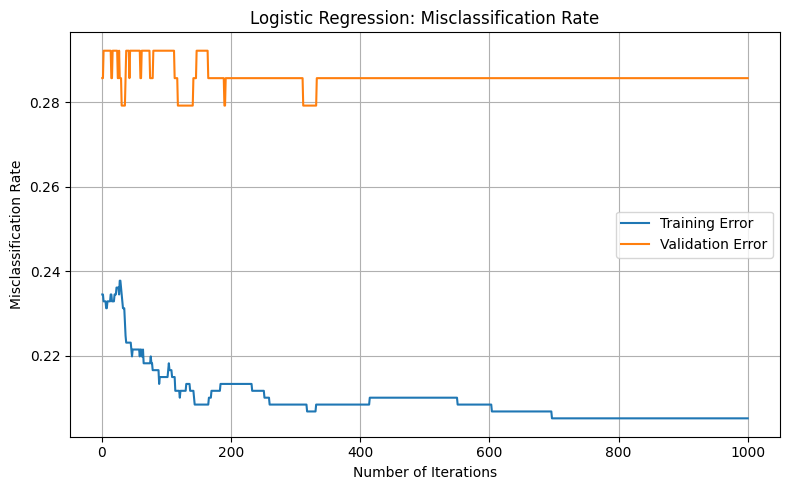

In [33]:
iteration_numbers = np.arange(1, iterations + 1)

plt.figure(figsize=(8, 5))
plt.plot(iteration_numbers, history["training_error"], label="Training Error")
plt.plot(iteration_numbers, history["validation_error"], label="Validation Error")
plt.xlabel("Number of Iterations")
plt.ylabel("Misclassification Rate")
plt.title("Logistic Regression: Misclassification Rate")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

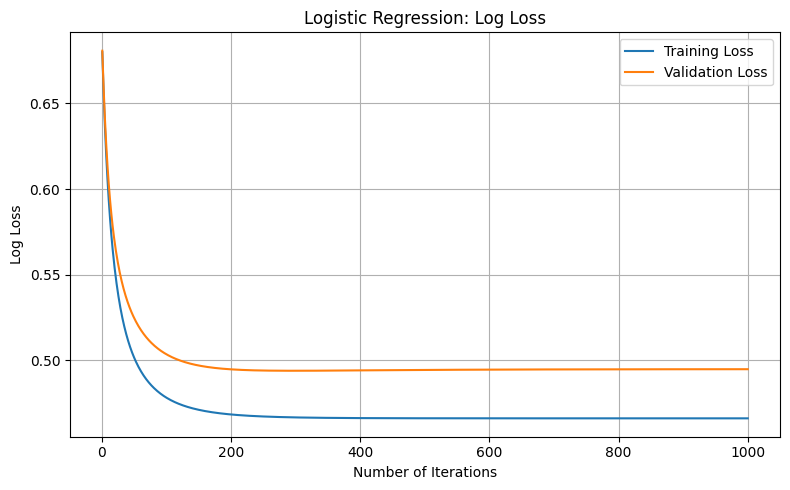

In [34]:
plt.figure(figsize=(8, 5))
plt.plot(iteration_numbers, history["training_loss"], label="Training Loss")
plt.plot(iteration_numbers, history["validation_loss"], label="Validation Loss")
plt.xlabel("Number of Iterations")
plt.ylabel("Log Loss")
plt.title("Logistic Regression: Log Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Gaussian Naive Bayes

Train GaussianNB on the same training data and evaluate it on the same validation set.

In [35]:
naive_bayes = GaussianNB()
naive_bayes.fit(X_train_scaled, y_train)
naive_bayes_predictions = naive_bayes.predict(X_validation_scaled)

naive_bayes_scores = evaluate_model(y_validation, naive_bayes_predictions, "Gaussian Naive Bayes")

Gaussian Naive Bayes
Validation confusion matrix:
          Predicted 0  Predicted 1
Actual 0           74           26
Actual 1           19           35
Validation metrics:
Accuracy     0.7078
Precision    0.5738
Recall       0.6481
F1 Score     0.6087


## Compare the Models

Show the validation scores of both models together.

In [36]:
comparison = pd.DataFrame(
    [logistic_scores, naive_bayes_scores],
    index=["Logistic Regression", "Gaussian Naive Bayes"]
)
print("Validation results:")
print(comparison.round(4).to_string())

Validation results:
                      Accuracy  Precision  Recall  F1 Score
Logistic Regression     0.7143     0.6087  0.5185    0.5600
Gaussian Naive Bayes    0.7078     0.5738  0.6481    0.6087
